In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
check_data = pd.read_excel(r'C:\IDE\2 семестр\Внедрение моделей ML\AB test\check_data.xlsx')
check_data.head()

,date,mean_check_a,mean_check_b
0,2020-11-06,68701.239649,88665.123322
1,2020-11-07,26136.309375,46230.394893
2,2020-11-08,119470.770656,139356.451490
3,2020-11-09,71110.880188,90867.073191
4,2020-11-10,85896.024022,105977.473589


In [3]:
check_data[['mean_check_a', 'mean_check_b']].agg(['mean', 'median'])

,mean_check_a,mean_check_b
mean,76684.763071,96658.897304
median,62883.707793,82854.201467


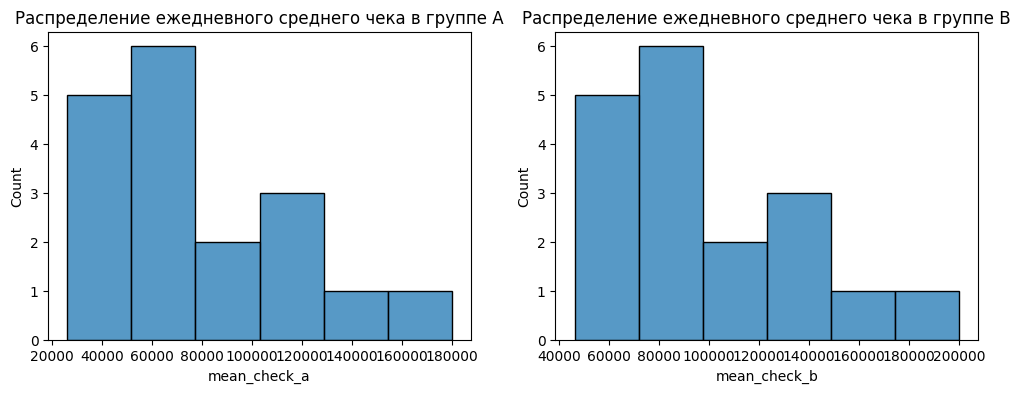

In [4]:
# создаём два графика размером 12x4
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# строим гистограмму для времени на сайте в каждой группе
sns.histplot(x='mean_check_a', data=check_data, ax=axes[0])
sns.histplot(x='mean_check_b', data=check_data, ax=axes[1])
# задаём названия графикам
axes[0].set_title('Распределение ежедневного среднего чека в группе А');
axes[1].set_title('Распределение ежедневного среднего чека в группе B');

In [5]:
from scipy.stats import mannwhitneyu

Давайте воспользуемся тестом Манна — Уитни, чтобы проверить, статистически значима ли разница ежедневных средних чеков для двух вариантов рекомендательной системы.

Для критерия Манна — Уитни гипотезы будут выглядеть следующим образом:

Нулевая гипотеза (об отсутствии эффекта): распределение, лежащее в основе среднего чека в группе А, идентично распределению, лежащему в основе среднего чека в группе B:


Альтернативная гипотеза (о наличии эффекта): распределение, лежащее в основе среднего чека в группе А, отлично от распределения, лежащего в основе среднего чека в группе B:

Функция принимает на вход следующие параметры:

x и y — выборки, соответствующие каждой из групп.
alternative — вид альтернативной гипотезы (‘two-sided’ — двусторонняя, 'less' — левосторонняя, 'greater’ — правосторонняя). По умолчанию используется двусторонняя гипотеза.

In [6]:
alpha = 0.05 # уровень значимости

# вычисляем результат теста Манна — Уитни для выборок
results = mannwhitneyu(
    x=check_data['mean_check_a'],
    y=check_data['mean_check_b'],
    alternative='two-sided'
)
print('p-value:', round(results.pvalue, 2))

# сравниваем полученное p-value с уровнем значимости
if results.pvalue <= alpha:
    print("Отвергаем нулевую гипотезу в пользу альтернативной")
else:
    print("У нас нет оснований отвергнуть нулевую гипотезу")

# p-value: 0.06
# У нас нет оснований отвергнуть нулевую гипотезу

p-value: 0.06
У нас нет оснований отвергнуть нулевую гипотезу


Однако нас должно насторожить, что p-value очень близко к уровню значимости. Поэтому давайте дополнительно проведём односторонний U-тест со следующими гипотезами:

Нулевая гипотеза (об отсутствии эффекта): распределение, лежащее в основе среднего чека в группе А, статистически больше либо равно распределению, лежащему в основе среднего чека в группе B:


Левосторонняя альтернативная гипотеза (о наличии эффекта): распределение, лежащее в основе среднего чека в группе А, статистически меньше распределения, лежащего в основе среднего чека в группе B:

In [7]:
alpha = 0.05 # уровень значимости

# вычисляем результат теста Манна — Уитни для выборок
results = mannwhitneyu(
    x=check_data['mean_check_a'],
    y=check_data['mean_check_b'],
    alternative='less' # изменили альтернативную гипотезу
)
print('p-value:', round(results.pvalue, 2))

# сравниваем полученное p-value с уровнем значимости
if results.pvalue <= alpha:
    print("Отвергаем нулевую гипотезу в пользу альтернативной")
else:
    print("У нас нет оснований отвергнуть нулевую гипотезу")

# p-value: 0.03
# Отвергаем нулевую гипотезу в пользу альтернативной

p-value: 0.03
Отвергаем нулевую гипотезу в пользу альтернативной
